# 05 — Ablasi Augmentasi (Opsi B, tambahan)

Pertanyaan: apakah menambahkan 8 salinan augmentasi bawaan dataset ke data latih membantu?

- **Opsi A** (eksperimen utama, notebook 03–04): latih dengan 457 foto asli.
- **Opsi B** (notebook ini): latih dengan 457 foto asli **ditambah** 8 augmentasinya, total 4.113 citra.

Aturan supaya perbandingannya adil:

1. **Validasi hanya memakai foto asli.** Di tiap fold, salinan augmentasi dari foto validasi dibuang dari `val_idx`, supaya skor validasi Opsi B dihitung pada jenis data yang sama dengan Opsi A dan data uji.
2. **Fold sama dengan Opsi A.** Pembagian `origin_id` ke 5 fold dibuat ulang persis seperti di notebook 03. Augmentasi selalu ikut fold foto aslinya, sehingga salinan foto validasi tidak pernah ada di data latih fold tersebut.
3. **Data uji sama**: 115 foto asli yang sama, dievaluasi sekali per model setelah hyperparameter dibekukan.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
t0 = time.time()

from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from src.features import extract_table, scenario_columns
from src.evaluate import summarize, compare

FIG_DIR = config.FIGURES_DIR / "05_ablasi"
FIG_DIR.mkdir(parents=True, exist_ok=True)
feats = pd.read_csv(config.FEATURES_DIR / "features_train.csv")
feats_te = pd.read_csv(config.FEATURES_DIR / "features_test.csv")
cvA = pd.read_csv(config.RESULTS_DIR / "cv_results.csv")
teA = pd.read_csv(config.RESULTS_DIR / "test_results.csv")
SCEN = scenario_columns(feats.columns)
print(f"Latih Opsi B: {len(feats)} citra ({(feats['aug_type'] == 'original').sum()} asli); uji: {len(feats_te)} foto asli")

Latih Opsi B: 4113 citra (457 asli); uji: 115 foto asli


## 1. Fold: sama dengan Opsi A, validasi hanya foto asli

Fold Opsi A dibuat ulang dari tabel foto asli dengan parameter yang sama (`StratifiedGroupKFold`, 5 fold, `shuffle=True`, `random_state=42`). Lalu setiap `origin_id` dipetakan ke nomor fold-nya:

- `train_idx` = semua baris (asli + augmentasi) yang `origin_id`-nya **bukan** di fold k;
- `val_idx` = hanya baris **foto asli** yang `origin_id`-nya di fold k.

In [2]:
dA = feats[feats["aug_type"] == "original"].reset_index(drop=True)
cv = StratifiedGroupKFold(n_splits=config.N_FOLDS, shuffle=True, random_state=config.SEED)
foldsA = list(cv.split(dA, dA["label"], dA["origin_id"]))
fold_of = {oid: k for k, (_, va) in enumerate(foldsA) for oid in dA["origin_id"].iloc[va]}

fold_id = feats["origin_id"].map(fold_of).to_numpy()
is_orig = (feats["aug_type"] == "original").to_numpy()
foldsB = [(np.where(fold_id != k)[0], np.where((fold_id == k) & is_orig)[0]) for k in range(config.N_FOLDS)]

for k, (tr, va) in enumerate(foldsB):
    assert set(feats["origin_id"].iloc[tr]).isdisjoint(feats["origin_id"].iloc[va])
    assert (feats["aug_type"].iloc[va] == "original").all()
    assert len(va) == len(foldsA[k][1])
    print(f"fold {k}: latih {len(tr)} citra, validasi {len(va)} foto asli")

fold 0: latih 3285 citra, validasi 92 foto asli
fold 1: latih 3285 citra, validasi 92 foto asli
fold 2: latih 3294 citra, validasi 91 foto asli
fold 3: latih 3294 citra, validasi 91 foto asli
fold 4: latih 3294 citra, validasi 91 foto asli


## 2. Grid search Opsi B

Grid, kernel, dan metrik sama dengan Opsi A. Karena data latih kira-kira 9× lebih besar, training SVM lebih lama (kompleksitas SVM tumbuh lebih dari linear terhadap jumlah sampel).

In [3]:
y = feats["label"].to_numpy()
rows, searches = [], {}
t = time.time()
for scen, cols in SCEN.items():
    X = feats[cols].to_numpy()
    for kernel in ["linear", "rbf", "poly"]:
        pipe = Pipeline([("scaler", StandardScaler()),
                         ("svc", SVC(kernel=kernel, class_weight="balanced"))])
        gs = GridSearchCV(pipe, config.PARAM_GRIDS[kernel], cv=foldsB,
                          scoring={"f1_macro": "f1_macro", "accuracy": "accuracy"},
                          refit="f1_macro", n_jobs=-1)
        gs.fit(X, y)
        searches[(scen, kernel)] = gs
        r, b = gs.cv_results_, gs.best_index_
        f1f = [r[f"split{k}_test_f1_macro"][b] for k in range(config.N_FOLDS)]
        accf = [r[f"split{k}_test_accuracy"][b] for k in range(config.N_FOLDS)]
        rows.append({"scenario": scen, "kernel": kernel,
                     "best_params": {k.replace("svc__", ""): v for k, v in gs.best_params_.items()},
                     "f1_macro_mean": np.mean(f1f), "f1_macro_std": np.std(f1f),
                     "accuracy_mean": np.mean(accf), "accuracy_std": np.std(accf),
                     **{f"f1_fold{k}": v for k, v in enumerate(f1f)}})
    print(f"{scen} selesai ({time.time() - t:.0f} detik)")
cvB = pd.DataFrame(rows)

S1 selesai (18 detik)


S2 selesai (27 detik)


S3 selesai (40 detik)


S4 selesai (52 detik)


## 3. Evaluasi data uji Opsi B

Model terbaik tiap kombinasi skenario × kernel (sudah di-*refit* oleh `GridSearchCV` pada seluruh 4.113 citra latih) memprediksi 115 foto uji yang sama dengan Opsi A, satu kali.

In [4]:
testB = []
for (scen, kernel), gs in searches.items():
    pred = gs.predict(feats_te[SCEN[scen]].to_numpy())
    testB.append({"scenario": scen, "kernel": kernel, **summarize(feats_te["label"], pred)})
testB = pd.DataFrame(testB)

abl = cvB.merge(testB, on=["scenario", "kernel"])
abl = abl.rename(columns={"accuracy": "test_accuracy", "f1_macro": "test_f1_macro"})
A = cvA[["scenario", "kernel", "f1_macro_mean", "f1_macro_std"]].merge(
    teA[["scenario", "kernel", "f1_macro", "accuracy"]], on=["scenario", "kernel"]).rename(columns={
    "f1_macro_mean": "A_cv_f1_mean", "f1_macro_std": "A_cv_f1_std", "f1_macro": "A_test_f1_macro", "accuracy": "A_test_accuracy"})
abl = abl.merge(A, on=["scenario", "kernel"])
abl["status_cv_B_vs_A"] = [compare(r.f1_macro_mean, r.f1_macro_std, r.A_cv_f1_mean, r.A_cv_f1_std) for r in abl.itertuples()]
abl.insert(0, "option", "B")
abl.to_csv(config.RESULTS_DIR / "ablation_aug.csv", index=False)
print("Disimpan: results/ablation_aug.csv")

Disimpan: results/ablation_aug.csv


In [5]:
view = pd.DataFrame({
    "skenario": abl["scenario"], "kernel": abl["kernel"],
    "F1 CV A": abl.apply(lambda r: f"{r.A_cv_f1_mean:.3f} ± {r.A_cv_f1_std:.3f}", axis=1),
    "F1 CV B": abl.apply(lambda r: f"{r.f1_macro_mean:.3f} ± {r.f1_macro_std:.3f}", axis=1),
    "selisih CV (B−A)": (abl["f1_macro_mean"] - abl["A_cv_f1_mean"]).round(3),
    "status B > A (CV)": abl["status_cv_B_vs_A"],
    "F1 uji A": abl["A_test_f1_macro"].round(3), "F1 uji B": abl["test_f1_macro"].round(3),
    "param B": abl["best_params"],
})
view

,skenario,kernel,F1 CV A,F1 CV B,selisih CV (B−A),status B > A (CV),F1 uji A,F1 uji B,param B
0,S1,linear,0.927 ± 0.016,0.927 ± 0.016,-0.001,tidak meyakinkan,0.923,0.914,{'C': 100}
1,S1,rbf,0.954 ± 0.007,0.987 ± 0.011,0.033,didukung,0.965,0.982,"{'C': 100, 'gamma': 0.1}"
2,S1,poly,0.930 ± 0.034,0.977 ± 0.007,0.047,didukung,0.983,1.000,"{'C': 100, 'degree': 2, 'gamma': 1}"
3,S2,linear,0.980 ± 0.011,0.980 ± 0.013,0.000,tidak meyakinkan,1.000,1.000,{'C': 100}
4,S2,rbf,0.973 ± 0.027,0.995 ± 0.009,0.022,tidak meyakinkan,1.000,1.000,"{'C': 100, 'gamma': 0.1}"
5,S2,poly,0.974 ± 0.018,0.995 ± 0.009,0.022,didukung,1.000,1.000,"{'C': 10, 'degree': 2, 'gamma': 1}"
6,S3,linear,0.916 ± 0.004,0.976 ± 0.014,0.060,didukung,0.916,0.927,{'C': 1}
7,S3,rbf,0.938 ± 0.033,0.987 ± 0.010,0.049,didukung,0.953,1.000,"{'C': 100, 'gamma': 0.01}"
8,S3,poly,0.892 ± 0.035,0.949 ± 0.026,0.056,didukung,0.896,0.982,"{'C': 0.1, 'degree': 3, 'gamma': 1}"
9,S4,linear,0.950 ± 0.013,0.989 ± 0.010,0.039,didukung,0.961,0.991,{'C': 10}


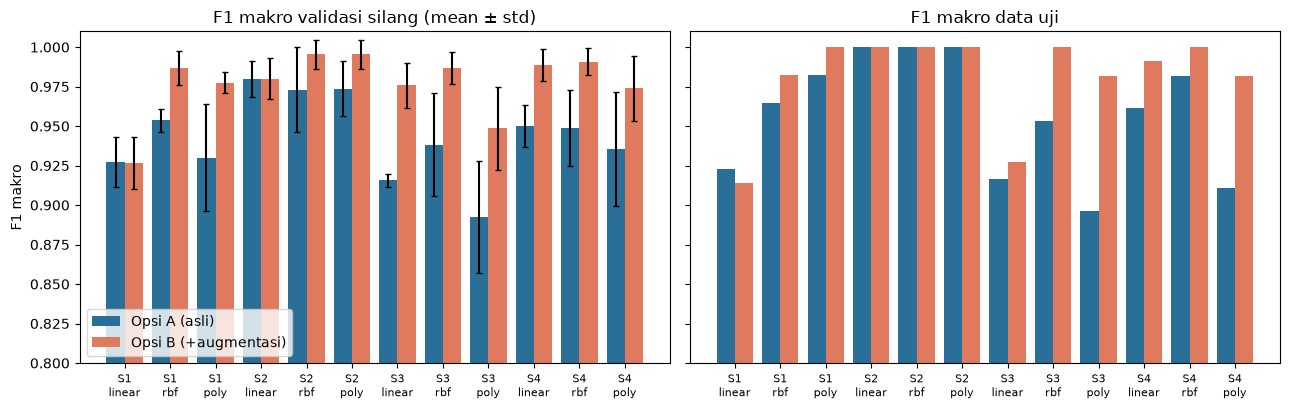

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
x = np.arange(len(abl))
labels = [f"{s}\n{k}" for s, k in zip(abl["scenario"], abl["kernel"])]
axes[0].bar(x - 0.2, abl["A_cv_f1_mean"], 0.4, yerr=abl["A_cv_f1_std"], capsize=2, label="Opsi A (asli)", color="#2a6f97")
axes[0].bar(x + 0.2, abl["f1_macro_mean"], 0.4, yerr=abl["f1_macro_std"], capsize=2, label="Opsi B (+augmentasi)", color="#e07a5f")
axes[0].set_title("F1 makro validasi silang (mean ± std)")
axes[1].bar(x - 0.2, abl["A_test_f1_macro"], 0.4, label="Opsi A", color="#2a6f97")
axes[1].bar(x + 0.2, abl["test_f1_macro"], 0.4, label="Opsi B", color="#e07a5f")
axes[1].set_title("F1 makro data uji")
for ax in axes:
    ax.set_xticks(x, labels, fontsize=8); ax.set_ylim(0.8, 1.01)
axes[0].set_ylabel("F1 makro"); axes[0].legend(loc="lower left")
fig.tight_layout()
fig.savefig(FIG_DIR / "opsi_a_vs_b.png", dpi=150)
plt.show()

## 4. Seberapa besar augmentasi mengubah fitur?

Catatan dari desain: `RandomRotate90`, `Transpose`, dan `Flip` hanya memutar atau mencerminkan citra. Untuk GLCM, ini sekadar menukar sudut (0° ↔ 90°, 45° ↔ 135°), sehingga fitur S2 yang dirata-rata 4 arah **hampir tidak berubah**: salinannya nyaris duplikat. Fitur S1 (0° saja) dan LBP `nri_uniform` (tidak invarian rotasi) justru berubah.

Untuk memeriksanya, dihitung jarak tiap augmentasi ke foto aslinya di ruang fitur ternormalisasi, relatif terhadap jarak rata-rata antar-foto asli yang berbeda.

In [7]:
orig = feats[feats["aug_type"] == "original"].set_index("origin_id")
rel = []
for scen in ["S1", "S2", "S3"]:
    cols = SCEN[scen]
    mu, sd = orig[cols].mean(), orig[cols].std()
    Z = (orig[cols] - mu) / sd
    rng = np.random.default_rng(config.SEED)
    a, b = rng.integers(0, len(Z), 2000), rng.integers(0, len(Z), 2000)
    keep = a != b
    base = np.linalg.norm(Z.to_numpy()[a[keep]] - Z.to_numpy()[b[keep]], axis=1).mean()
    for aug in config.AUG_TYPES:
        sub = feats[feats["aug_type"] == aug].set_index("origin_id")
        d = np.linalg.norm(((sub[cols] - mu) / sd).to_numpy() - Z.loc[sub.index].to_numpy(), axis=1)
        rel.append({"skenario": scen, "augmentasi": aug, "jarak relatif": d.mean() / base})
rel = pd.DataFrame(rel).pivot(index="augmentasi", columns="skenario", values="jarak relatif")
rel.round(3)

skenario,S1,S2,S3
augmentasi,,,
ChannelShuffle,0.094,0.101,0.128
ElasticTransform,0.209,0.172,0.443
FDA,0.068,0.077,0.103
Flip,0.005,0.006,0.359
RandomGridShuffle,0.015,0.011,0.063
RandomRotate90,0.192,0.006,0.439
Sharpen,1.044,1.042,1.097
Transpose,0.334,0.006,0.584


Nilai 0 berarti salinan identik dengan aslinya di ruang fitur; nilai 1 berarti sejauh dua foto asli yang berbeda.

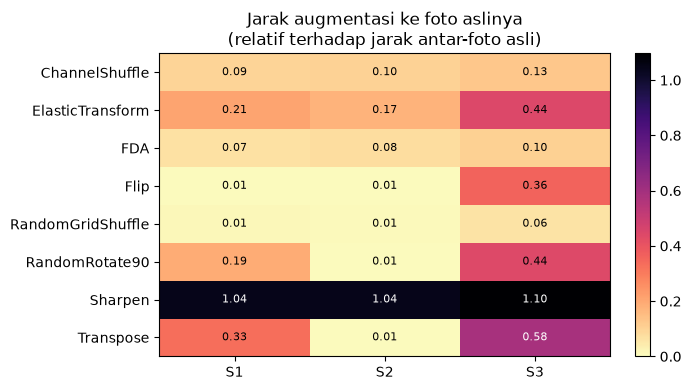

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(rel.values, cmap="magma_r", vmin=0, aspect="auto")
ax.set_xticks(range(rel.shape[1]), rel.columns); ax.set_yticks(range(rel.shape[0]), rel.index)
for i in range(rel.shape[0]):
    for j in range(rel.shape[1]):
        ax.text(j, i, f"{rel.values[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if rel.values[i, j] > rel.values.max() / 2 else "black")
ax.set_title("Jarak augmentasi ke foto aslinya\n(relatif terhadap jarak antar-foto asli)")
fig.colorbar(im, ax=ax, fraction=0.04)
fig.tight_layout()
fig.savefig(FIG_DIR / "jarak_augmentasi.png", dpi=150)
plt.show()

## 5. Pembahasan

Semua angka berasal dari tabel perbandingan dan tabel jarak augmentasi di atas. Status "B > A" memakai aturan yang sama dengan notebook 04: selisih F1 CV lebih kecil dari std terbesar → *tidak meyakinkan*.

### Augmentasi membantu pada 9 dari 12 model

- **LBP (S3) paling diuntungkan:** F1 CV naik 0,049–0,060, misalnya linear 0,916 → 0,976 dan RBF 0,938 → 0,987. Semuanya *didukung*.
- **Fusi (S4)** naik 0,038–0,042 di ketiga kernel (*didukung*).
- **S1** naik pada RBF (+0,033) dan polynomial (+0,047), tetapi tidak pada linear (−0,001).
- **S2 paling sedikit diuntungkan:** linear tidak berubah (0,980 → 0,980), RBF dan polynomial naik 0,022, tetapi RBF masih di bawah std.

### Kenapa S2 hampir tidak diuntungkan: augmentasi geometris adalah duplikat bagi GLCM 4 arah

Tabel jarak menunjukkan bahwa untuk S2, `Flip`, `RandomRotate90`, dan `Transpose` hanya bergeser 0,006 dari aslinya. Artinya salinannya praktis identik dengan foto asli. Ini sesuai catatan desain: memutar atau mencerminkan citra hanya menukar sudut GLCM (0° ↔ 90°, 45° ↔ 135°), dan rata-rata 4 sudut tidak berubah. Bagi S2, sebagian besar augmentasi tidak menambah informasi baru.

Pada S1 (0° saja), `RandomRotate90` (0,192) dan `Transpose` (0,334) menggeser fitur cukup jauh, karena sudut 0° berubah menjadi 90°. `Flip` tetap hampir nol (0,005): cermin horizontal hanya membalik urutan pasangan piksel (matriks GLCM menjadi transposenya), dan keempat ukuran GLCM bernilai sama untuk matriks dan transposenya; cermin vertikal tidak mengubah pasangan horizontal sama sekali.

Pada S3, LBP `nri_uniform` tidak invarian rotasi, sehingga `Flip` (0,359), `RandomRotate90` (0,439), dan `Transpose` (0,584) menghasilkan histogram yang benar-benar berbeda. Model LBP jadi belajar bahwa motif yang sama bisa muncul dalam berbagai orientasi. Ini dugaan yang paling sesuai dengan data mengapa S3 naik paling banyak (belum diuji langsung, misalnya dengan melatih hanya pada augmentasi geometris).

### Sharpen mengubah fitur sejauh foto yang berbeda

`Sharpen` menggeser fitur sekitar 1,04–1,10 di ketiga skenario. Artinya, satu foto yang di-sharpen berjarak di ruang fitur sejauh dua foto asli yang berbeda. Ini mendukung dua keputusan desain:

- **tanpa sharpening di preprocessing**, karena sharpening mengubah tekstur yang diukur GLCM/LBP secara drastis;
- **augmentasi tidak boleh ada di data uji**, karena salinan `Sharpen` akan menjadi data uji dengan distribusi fitur yang berbeda dari foto asli.

### Dampak ke hipotesis bila memakai Opsi B

Dengan Opsi B, selisih antar-skenario menyempit karena semua skor mendekati maksimum:

- S2 RBF 0,995 ± 0,009;
- S4 RBF 0,991 ± 0,009;
- S1 RBF 0,987 ± 0,011;
- S3 RBF 0,987 ± 0,010.

Perbandingan H1 dan H3 pada Opsi B menjadi *tidak meyakinkan*, karena selisihnya lebih kecil dari std. Kesimpulan hipotesis utama tetap memakai **Opsi A** sesuai desain, sedangkan Opsi B mengisyaratkan (dugaan, belum diuji terpisah) bahwa keunggulan S2 di Opsi A sebagian berasal dari sifatnya yang hampir tidak berubah terhadap rotasi dan pencerminan; augmentasi seolah "meminjamkan" sifat itu ke S1 dan S3.

### Data uji tidak lagi bisa membedakan

Pada Opsi B, 6 dari 12 model mencapai F1 uji 1,000, dan sisanya 0,914–0,991. Dengan 115 foto, data uji sudah jenuh (*ceiling effect*), jadi perbandingan Opsi A vs B lebih tepat dibaca dari validasi silang.

### Batasan

Batasan "kain yang sama" dari notebook 04 berlaku juga di sini, dan kemungkinan lebih kuat: augmentasi menambah salinan dari kain-kain yang sama, sehingga model makin hafal kain-kain tersebut. Kenaikan skor Opsi B belum tentu berarti generalisasi yang lebih baik ke kain baru.

In [9]:
print(f"Waktu jalan notebook: {time.time() - t0:.0f} detik")

Waktu jalan notebook: 54 detik
